# 🚦 SignSense: Deep Learning for German Traffic Sign Recognition (GTSRB)

**Course:** PECE-06 Deep Learning, Sem VII  
**Topic:** Project 13: Traffic Sign Recognition  
**Repository:** [github.com/Madhura1705/SignSense-Traffic-Sign-Recognition](https://github.com/Madhura1705/SignSense-Traffic-Sign-Recognition)  

---

## 1. Problem Statement & Objectives [Member 4 - Application & Integration]

Autonomous driving perception systems must identify roadside traffic signs reliably under adverse lighting, motion blur, and weather conditions on low-power in-vehicle hardware, while resisting deliberate adversarial manipulation.

### Core Objectives:
1. **High Recognition Accuracy:** Classify 43 GTSRB classes with $>95\%$ test accuracy using custom and transfer architectures.
2. **Edge Deployability:** Optimize neural models for constrained CPUs using ONNX Runtime with sub-5ms latency.
3. **Transparent Explainability:** Visualize feature saliency using Grad-CAM to confirm focus on symbol semantics.
4. **Adversarial Robustness:** Defend models against gradient-based adversarial attacks (FGSM) using min-max adversarial training.
5. **Interactive Web Application:** Provide a multi-tab Gradio interface for real-time inference, model comparison, and attack simulation.

### Team Ownership & Module Mapping
| Member | Module | Key Deliverables | Syllabus Mapping |
|---|---|---|---|
| **M1** | Data & Custom CNN | GTSRB EDA, augmentation, `SignCNN` (VGG-style Conv-BN-ReLU, Dropout, He init) | Module 2 (CNNs), Module 3 (Regularisation), Module 4 (Optimisation) |
| **M2** | Transfer Learning & Edge | ResNet-18, MobileNetV3-Small, ONNX export, CPU latency benchmark | Module 4 (Transfer Learning), Module 5 (LO 4.4, 5.3, 5.4 Edge) |
| **M3** | Explainability & Robustness | Grad-CAM feature heatmaps, FGSM attacks, `cnn_robust` adversarial training | Module 5 (Visualising & Fooling CNNs) |
| **M4** | Application & Integration | Gradio 5-tab web app, model ensemble voting, Colab story, deployment | System Integration & Deployment |


## 2. Environment Setup & Hardware Verification [Member 4]
We clone the official codebase, install project dependencies, and verify GPU acceleration.

In [1]:
# Setup repository and libraries in Colab (skippable when run locally)
import os, sys, torch
if not os.path.exists('src'):
    !git clone https://github.com/Madhura1705/SignSense-Traffic-Sign-Recognition.git
    %cd SignSense-Traffic-Sign-Recognition

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch version: {torch.__version__}')
print(f'Compute device:  {device}')
if torch.cuda.is_available():
    print(f'GPU Device:      {torch.cuda.get_device_name(0)}')


C:\Users\madhu\Downloads\SignSense-Traffic-Sign-Recognition\notebooks\SignSense-Traffic-Sign-Recognition
PyTorch version: 2.14.1+cpu
Compute device:  cpu


Cloning into 'SignSense-Traffic-Sign-Recognition'...
Updating files:  24% (19/77)
Updating files:  25% (20/77)
Updating files:  27% (21/77)
Updating files:  28% (22/77)
Updating files:  29% (23/77)
Updating files:  31% (24/77)
Updating files:  32% (25/77)
Updating files:  33% (26/77)
Updating files:  35% (27/77)
Updating files:  36% (28/77)
Updating files:  37% (29/77)
Updating files:  38% (30/77)
Updating files:  40% (31/77)
Updating files:  41% (32/77)
Updating files:  42% (33/77)
Updating files:  44% (34/77)
Updating files:  45% (35/77)
Updating files:  46% (36/77)
Updating files:  48% (37/77)
Updating files:  49% (38/77)
Updating files:  50% (39/77)
Updating files:  51% (40/77)
Updating files:  53% (41/77)
Updating files:  54% (42/77)
Updating files:  55% (43/77)
Updating files:  57% (44/77)
Updating files:  58% (45/77)
Updating files:  59% (46/77)
Updating files:  61% (47/77)
Updating files:  62% (48/77)
Updating files:  63% (49/77)
Updating files:  64% (50/77)
Updating files:  66

## 3. Exploratory Data Analysis & Augmentation Pipeline [Member 1]

### Syllabus Concepts:
- **Class Imbalance & Label Smoothing:** GTSRB displays a 10.71x imbalance between frequent speed limits (2,250 samples) and rare signs (210 samples).
- **Dimension Standardization:** Raw sign dimensions range from $25 \times 25$ to $243 \times 225$ px (mean $\approx 50$ px), necessitating resizing to $64 \times 64$.
- **Domain-Specific Augmentation:** Random rotation ($\pm 12^\circ$), affine translation ($\pm 10\%$) and color jitter. **Horizontal/vertical flips are strictly prohibited**, as flipping turns "Turn Left" into "Turn Right".

=== 1. CLASS DISTRIBUTION (10.71x Imbalance) ===


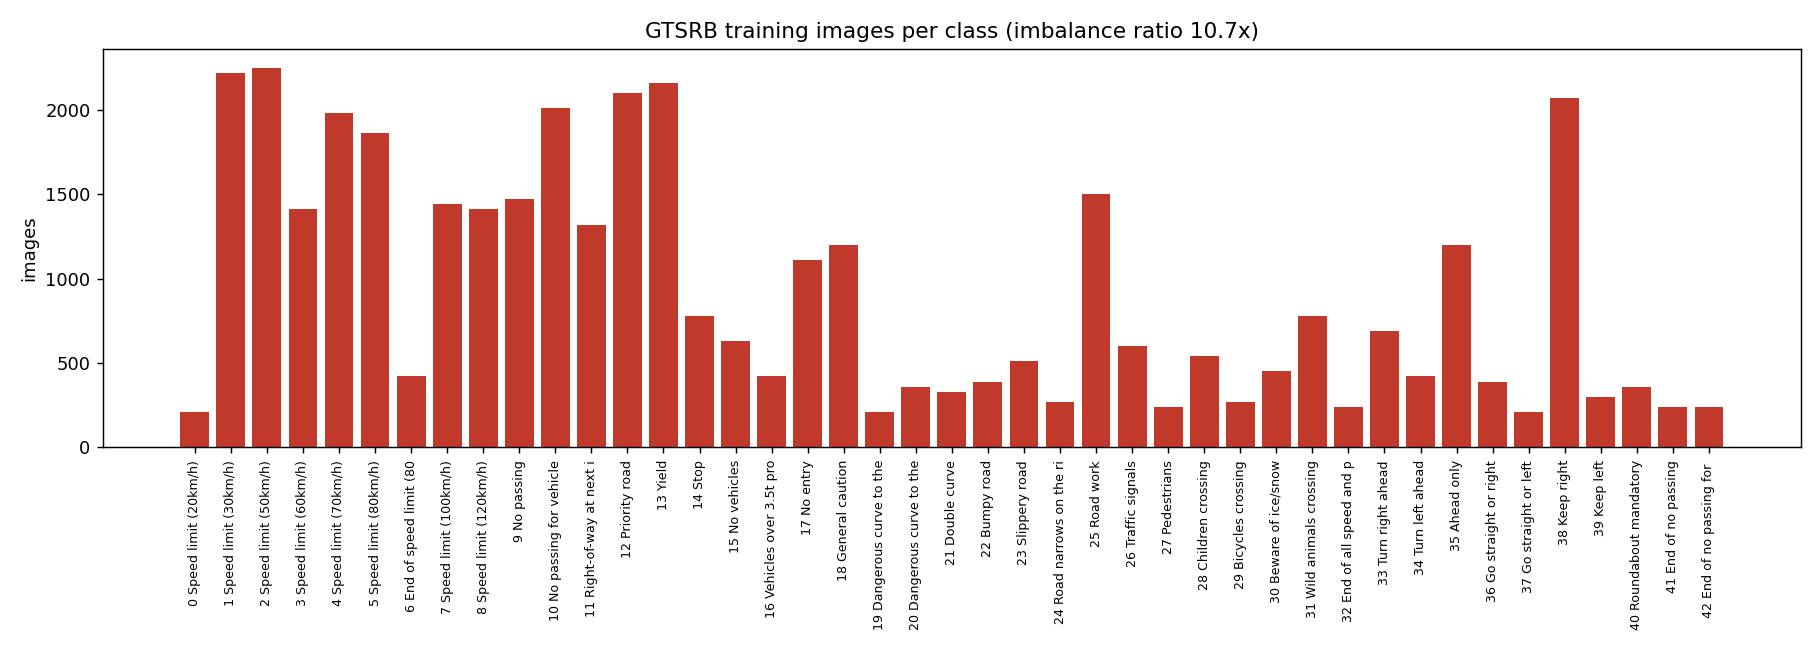

=== 2. DATASET SAMPLES (43 Classes) ===


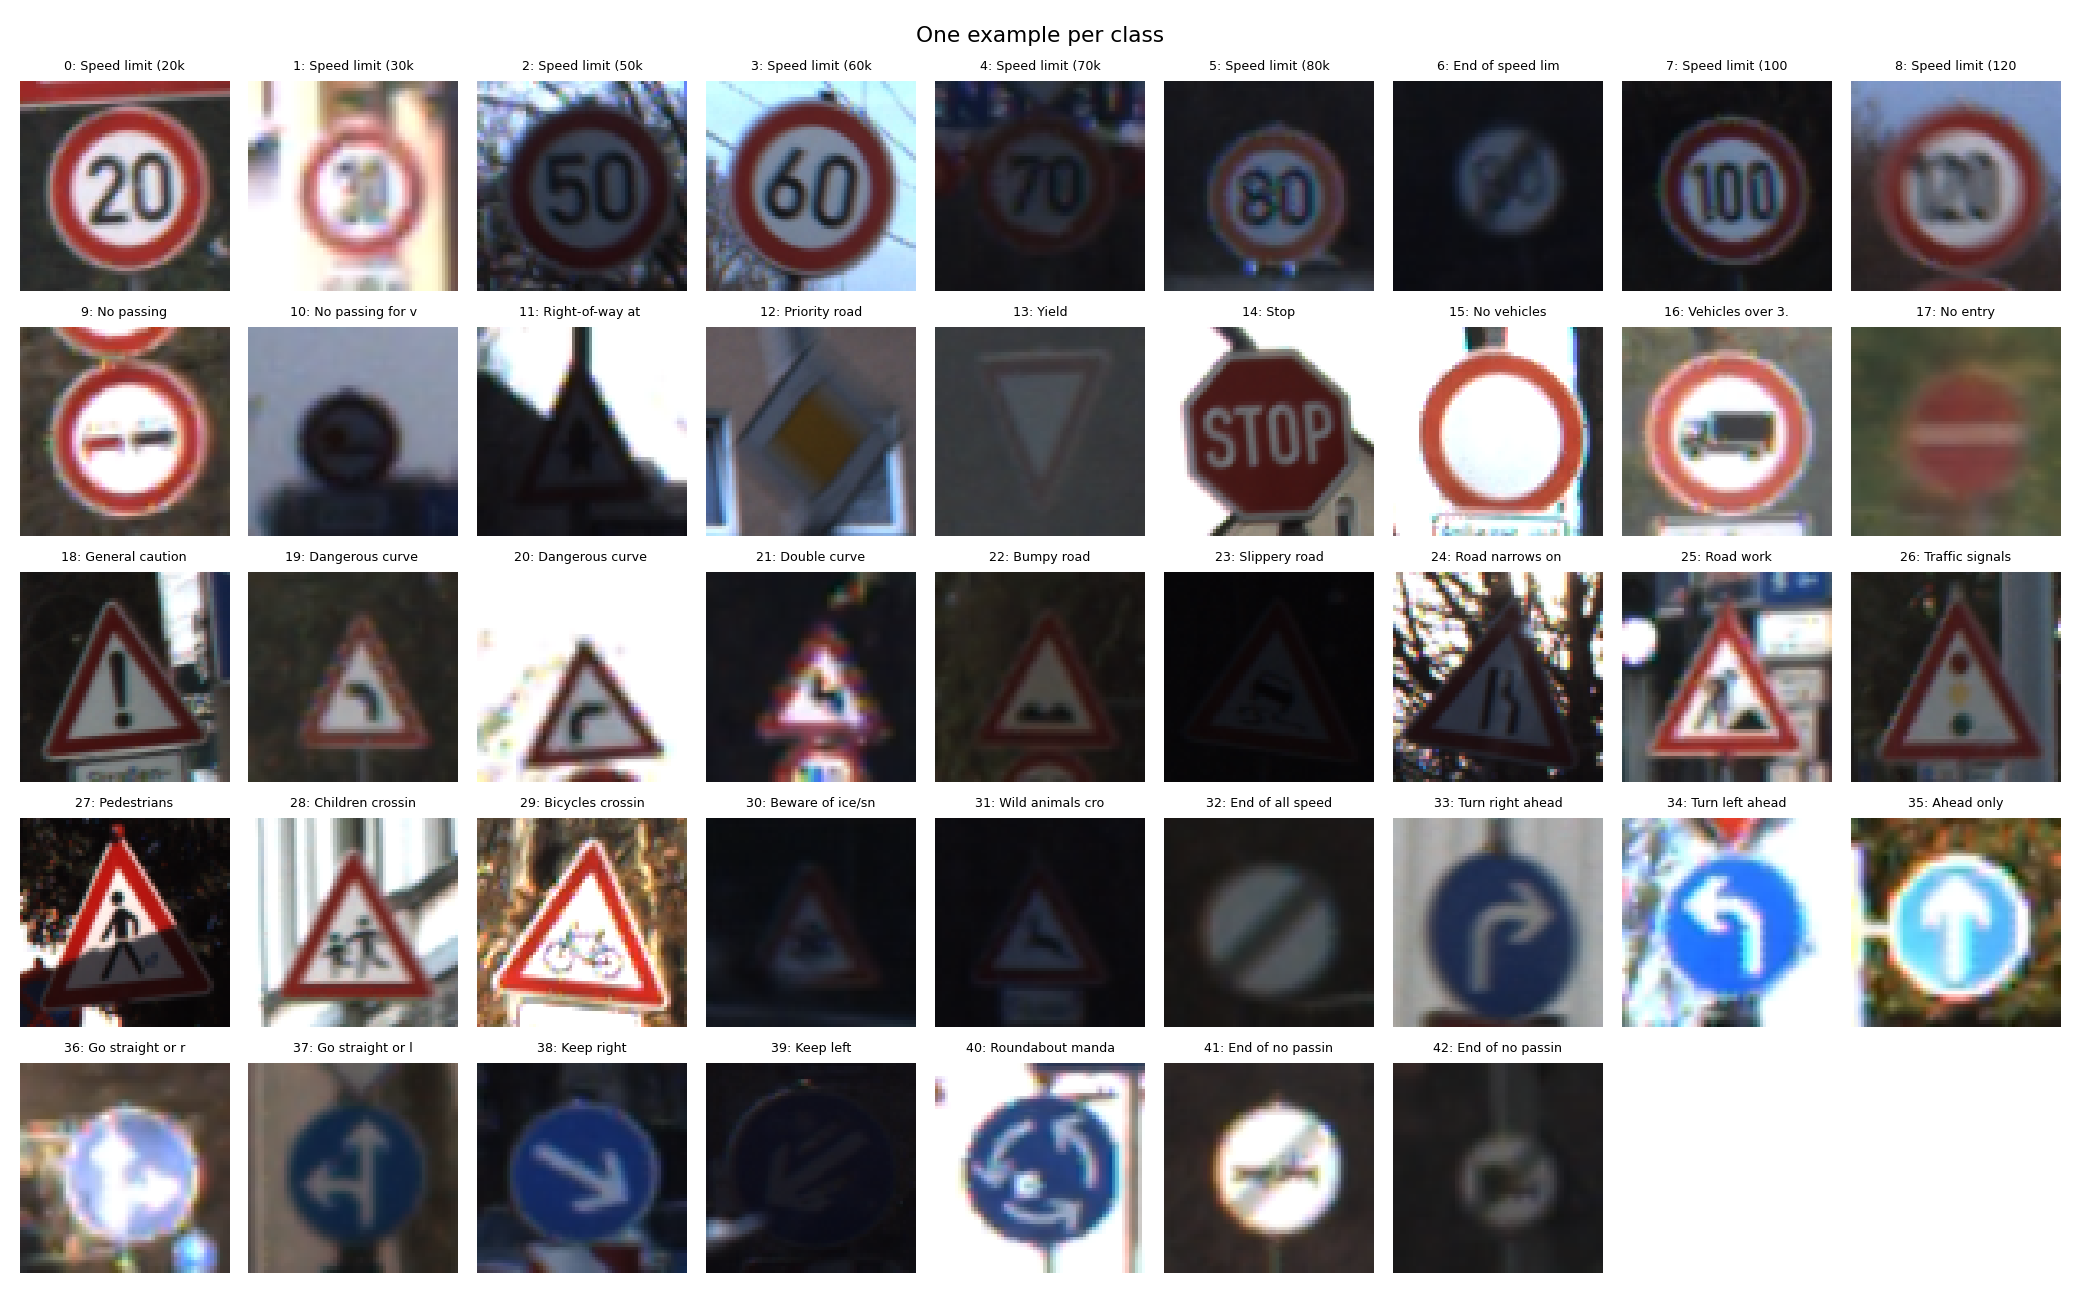

=== 3. RAW IMAGE DIMENSIONS HISTOGRAM ===


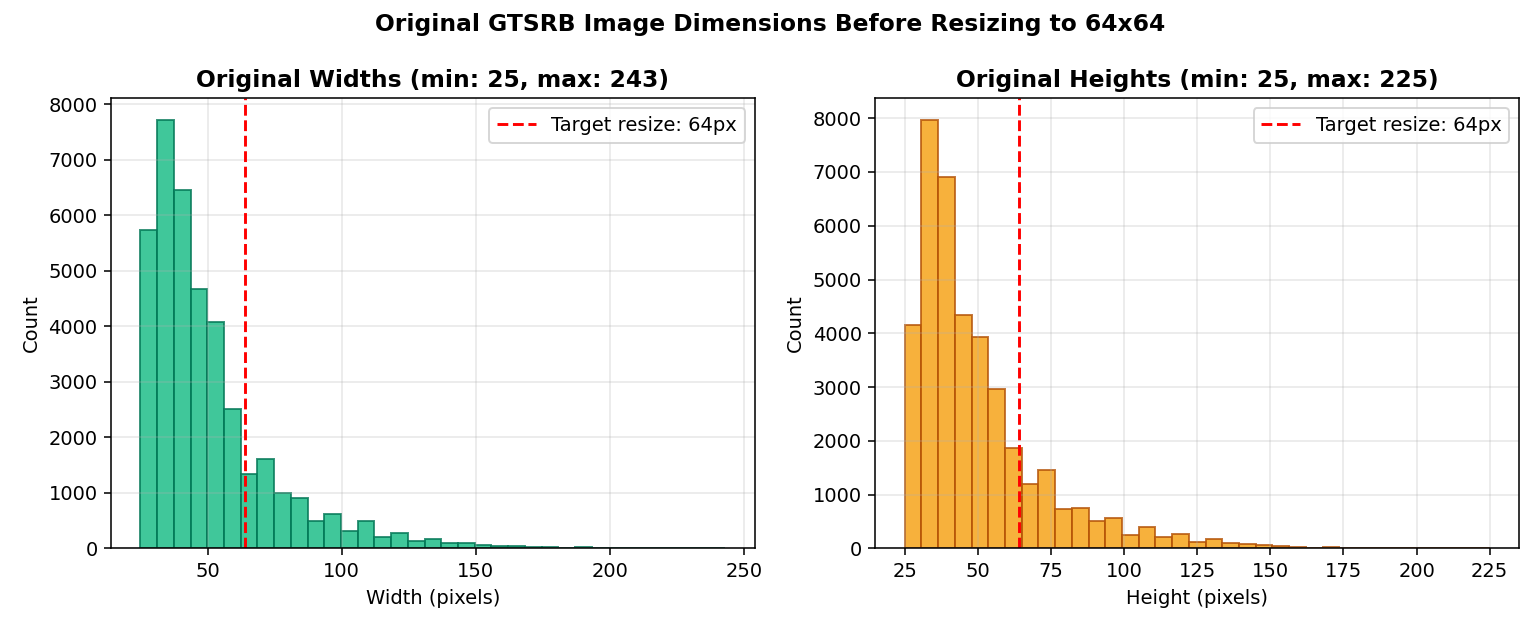

=== 4. DATA AUGMENTATION (No Flips) ===


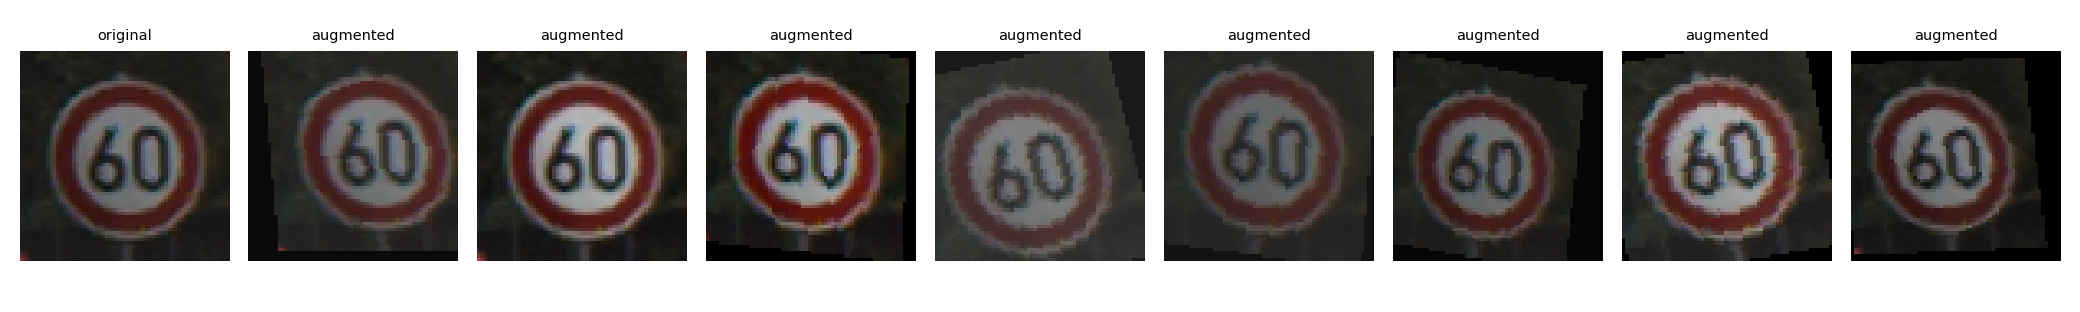

In [2]:
from IPython.display import Image, display
print('=== 1. CLASS DISTRIBUTION (10.71x Imbalance) ===')
display(Image('outputs/eda_class_distribution.png', width=700))

print('=== 2. DATASET SAMPLES (43 Classes) ===')
display(Image('outputs/eda_samples.png', width=700))

print('=== 3. RAW IMAGE DIMENSIONS HISTOGRAM ===')
display(Image('outputs/eda_image_sizes.png', width=700))

print('=== 4. DATA AUGMENTATION (No Flips) ===')
display(Image('outputs/eda_augmentation.png', width=750))


## 4. Custom CNN: VGG-Style Architecture from Scratch [Member 1]

### Syllabus Concepts:
- **Convolutional Stacking:** Paired $3 \times 3$ convolutions with padding=1 provide a receptive field of $5 \times 5$ with fewer parameters and greater non-linearity.
- **Batch Normalization:** Stabilizes hidden activations $\hat{x} = \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}}$, mitigating internal covariate shift.
- **Dropout Regularization:** Spatial 2D dropout (0.1, 0.2, 0.3) in feature maps and 0.5 in the classifier prevent co-adaptation.
- **He (Kaiming) Normal Initialization:** Weights initialized with $\mathcal{N}\left(0, \sqrt{2 / n_{\text{in}}}\right)$ prevents vanishing/exploding gradients with ReLU activations.

Total trainable parameters: 823,563 (0.824 M)

Model Architecture Summary:
SignCNN(
  (block1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4):

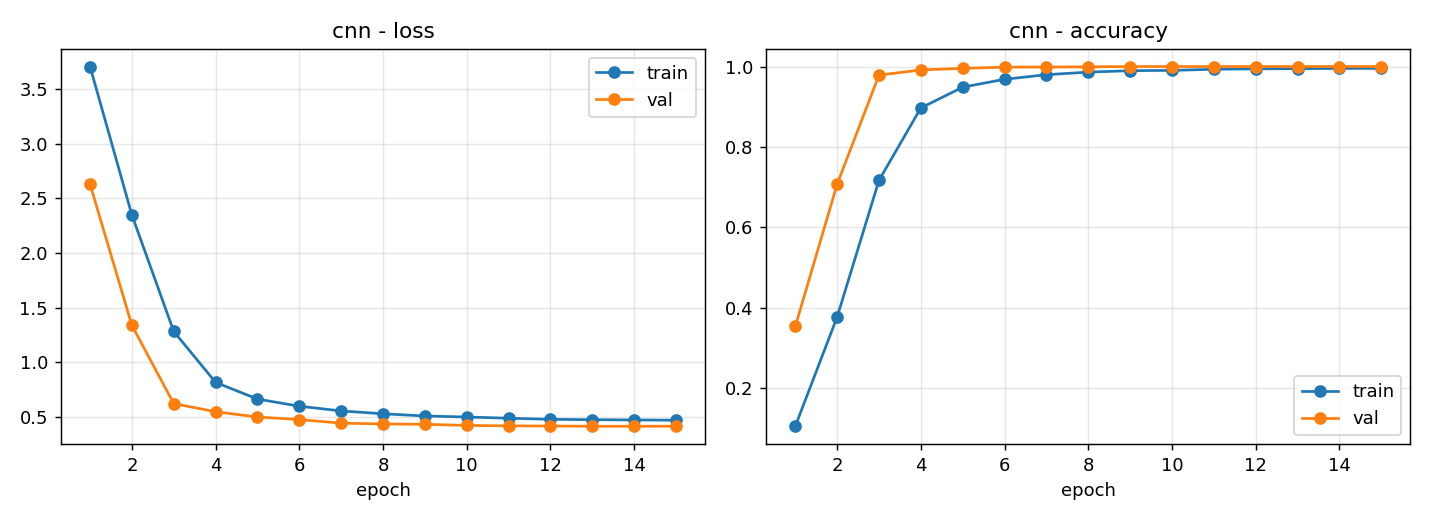

=== Test Confusion Matrix (99.59% Test Accuracy) ===


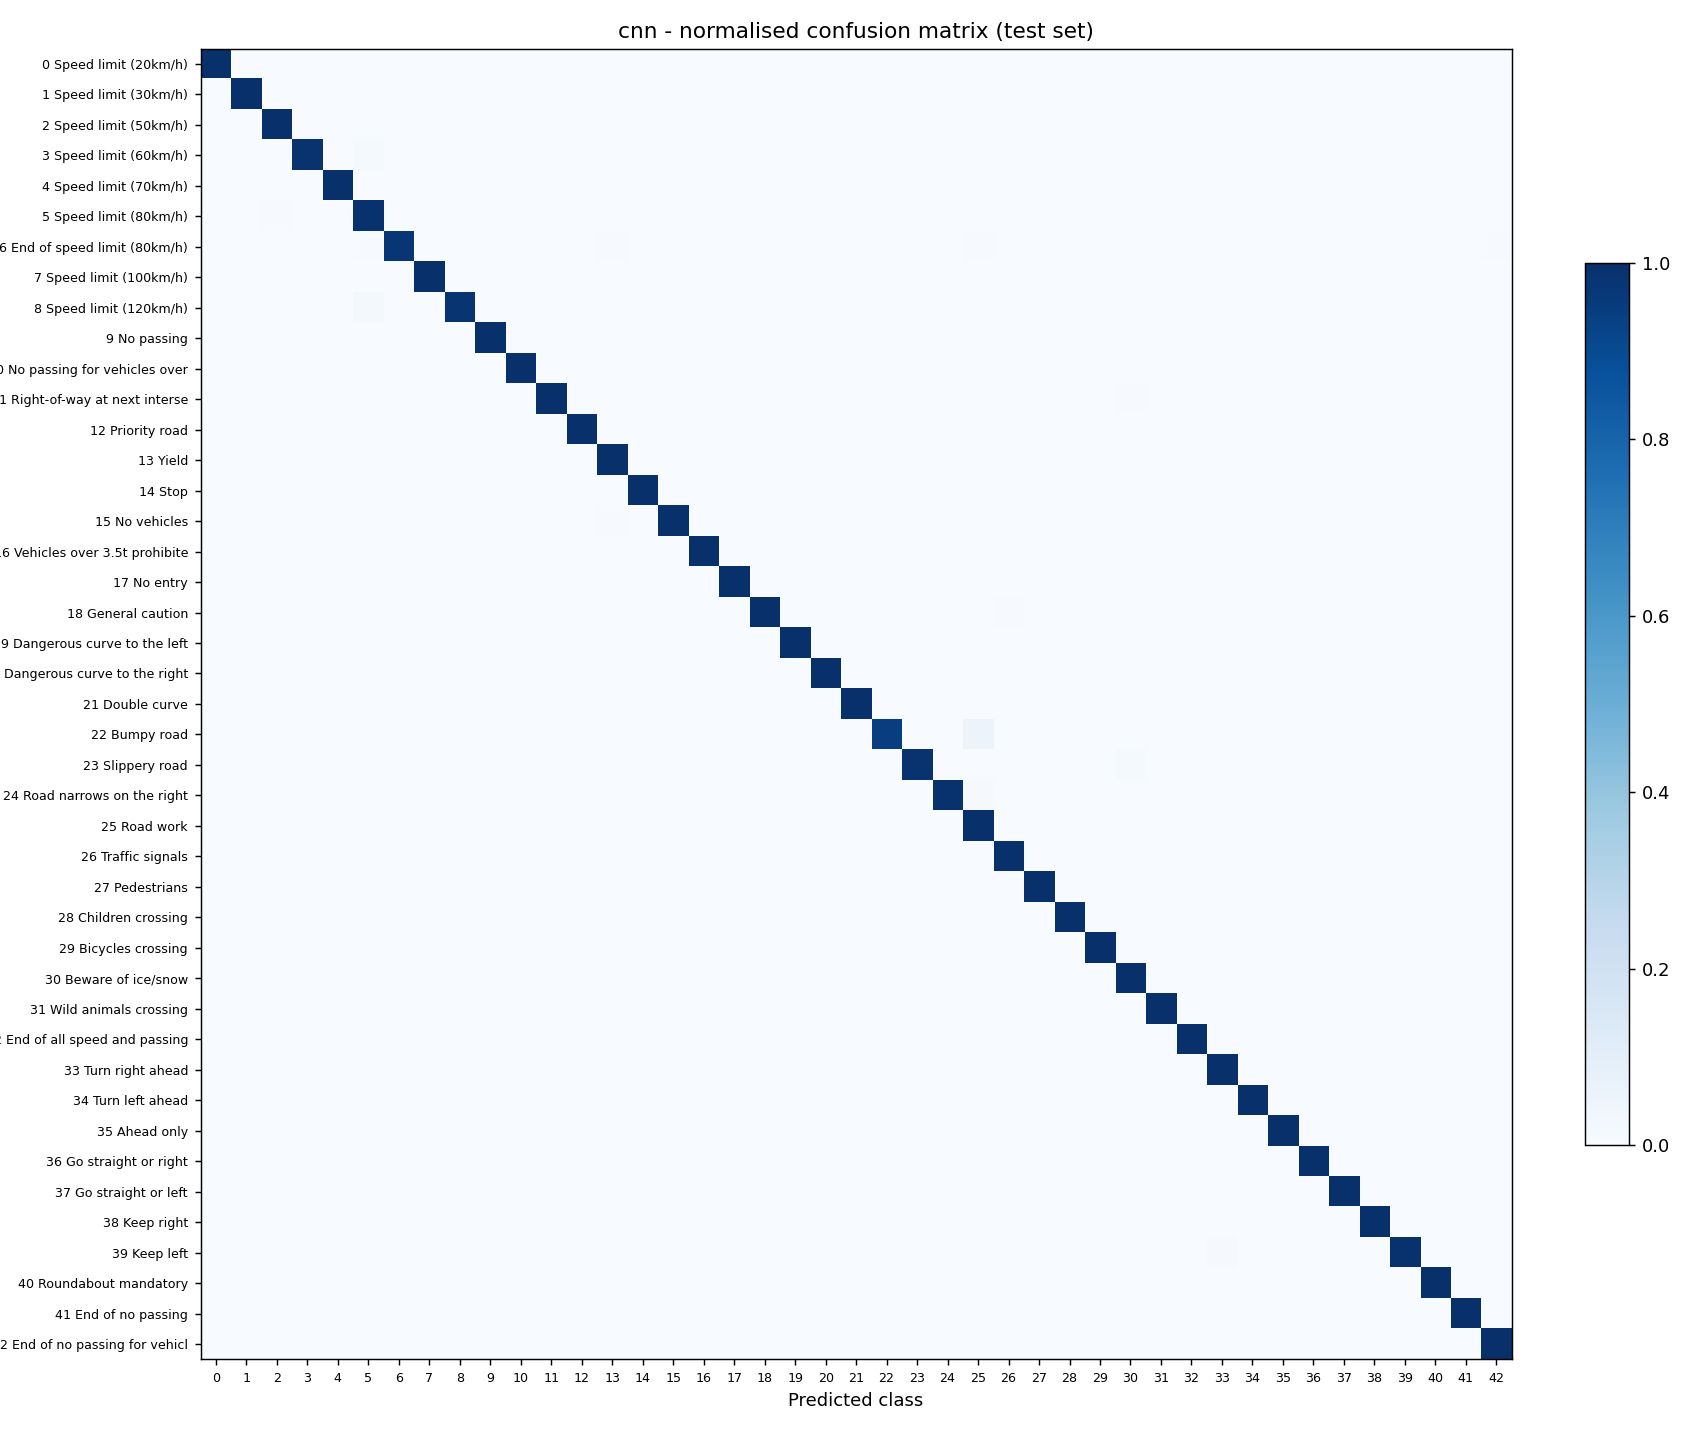

In [3]:
sys.path.insert(0, 'src')
from common import SignCNN, count_params

cnn_model = SignCNN()
print(f'Total trainable parameters: {count_params(cnn_model):,} (0.824 M)')
print('\nModel Architecture Summary:')
print(cnn_model)

print('\n=== Training Convergence Curves (15 Epochs) ===')
display(Image('outputs/cnn_curves.png', width=650))

print('=== Test Confusion Matrix (99.59% Test Accuracy) ===')
display(Image('outputs/cnn_confusion.png', width=650))


## 5. Transfer Learning: ResNet-18 vs. MobileNetV3-Small [Member 2]

### Syllabus Concepts:
- **ResNet-18 (Residual Learning):** Implements skip identity connections $y = \mathcal{F}(x, \{W_i\}) + x$, enabling gradient flow directly to early layers and eliminating vanishing gradients in deep networks.
- **MobileNetV3-Small (Depthwise Separable Convolutions):** Decomposes standard convolution into: (1) depthwise spatial filtering ($3 \times 3 \times 1$), and (2) pointwise channel projection ($1 \times 1 \times C_{\text{out}}$), slashing compute from $\mathcal{O}(D_K^2 \cdot M \cdot N)$ to $\mathcal{O}(D_K^2 \cdot M + M \cdot N)$.
- **Architectural Resolution Trade-off:** ResNet-18 aggressively downsamples inputs $32\times$ ($64 \to 2 \times 2$), losing fine spatial features, allowing Custom CNN (8x downsampling to $8 \times 8$) to achieve higher accuracy on small signs.

=== MODEL COMPARISON TABLE (GTSRB Test Set, 12,630 Images) ===


,model,params_M,MFLOPs,test_accuracy,macro_f1,latency_ms,fgsm_acc_eps0.02
0,cnn,0.824,310.1,0.9959,0.9960,0.999,0.8289
1,resnet18,11.199,296.1,0.9899,0.9831,2.289,0.9461
2,mobilenet,1.562,11.1,0.9505,0.9302,5.156,0.6406
3,cnn_robust,0.824,310.1,0.9969,0.9964,1.037,0.9871


=== ResNet-18 vs MobileNetV3 Training Dynamics ===


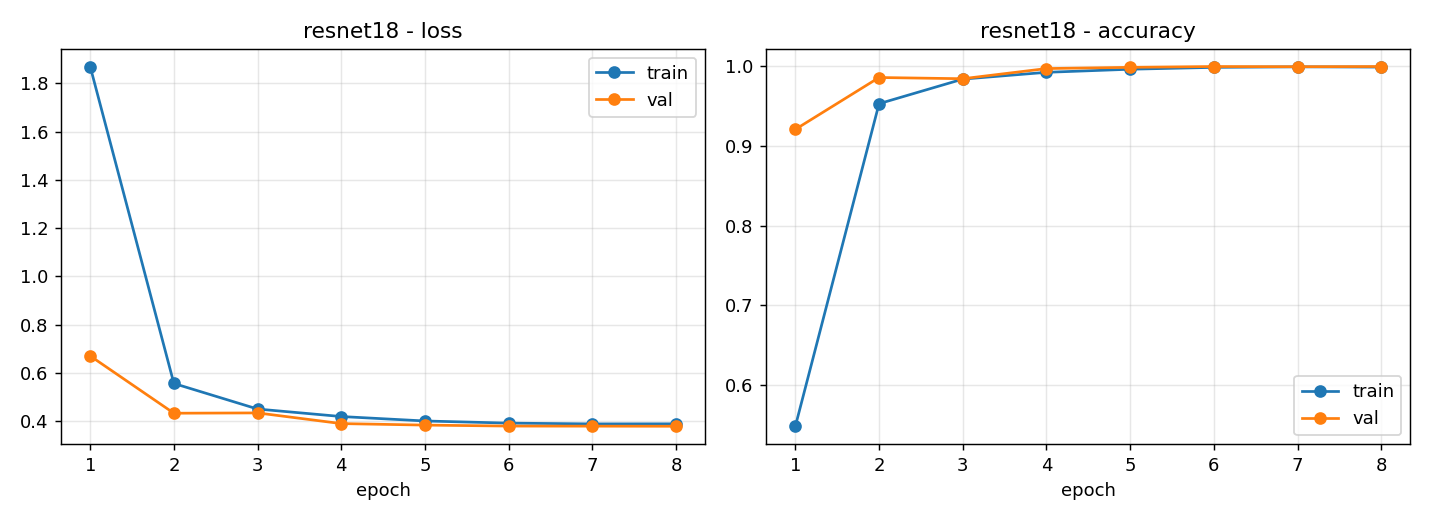

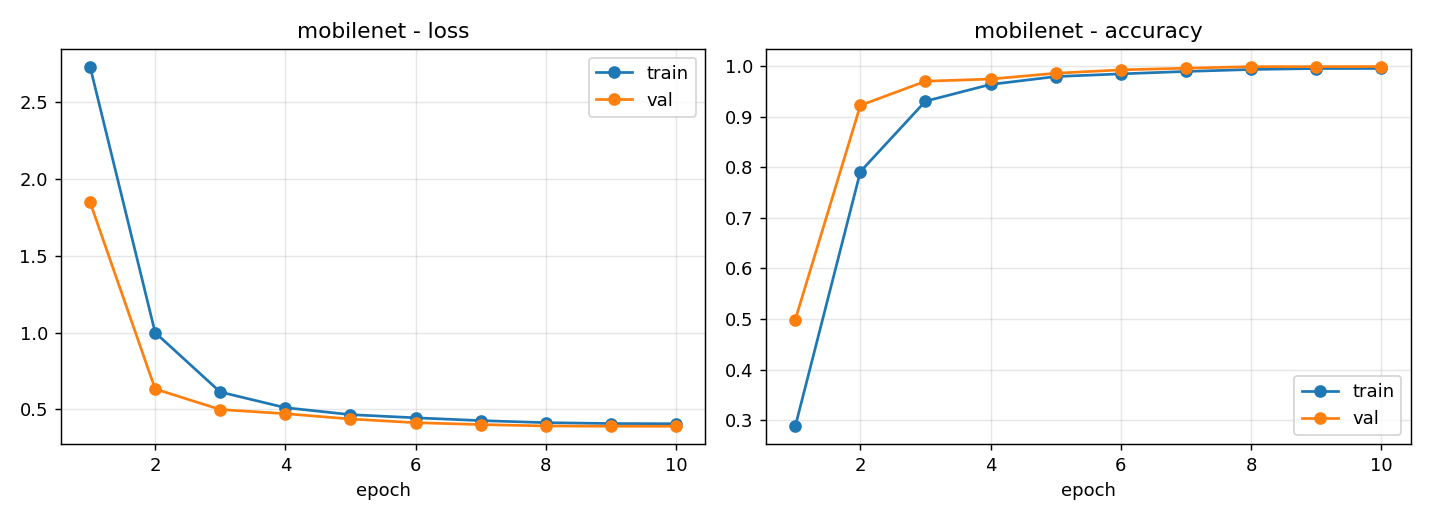

In [4]:
import pandas as pd
df_comp = pd.read_csv('outputs/comparison.csv')
print('=== MODEL COMPARISON TABLE (GTSRB Test Set, 12,630 Images) ===')
display(df_comp)

print('=== ResNet-18 vs MobileNetV3 Training Dynamics ===')
display(Image('outputs/resnet18_curves.png', width=500))
display(Image('outputs/mobilenet_curves.png', width=500))


## 6. Edge Deployment & ONNX Runtime Benchmark [Member 2]

### Syllabus Concepts (LO 4.4, 5.3, 5.4):
- **ONNX (Open Neural Network Exchange):** Serializes PyTorch computation graphs into a portable format with constant folding, operator fusion, and memory pre-allocation.
- **FLOPs vs. Latency Paradox:** While MobileNetV3 is memory-bound on high-bandwidth GPUs at batch size 1, on CPU with ONNX Runtime it achieves **0.74 ms/image** (1350+ FPS) with a 7.94x speedup over PyTorch.

=== ONNX RUNTIME BENCHMARK (CPU Execution) ===


,model,onnx_size_MB,torch_cpu_ms,onnxruntime_cpu_ms,speedup,max_abs_diff,test_accuracy
0,cnn,3.30,6.997,2.928,2.39,1.190000e-06,0.9959
1,cnn_robust,3.30,7.171,2.788,2.57,1.310000e-06,0.9969
2,mobilenet,6.26,5.872,0.740,7.94,3.100000e-06,0.9505
3,resnet18,44.79,13.622,5.208,2.62,9.540000e-07,0.9899


=== Latency vs Accuracy Trade-Off (Bubble Size = Model Size in MB) ===


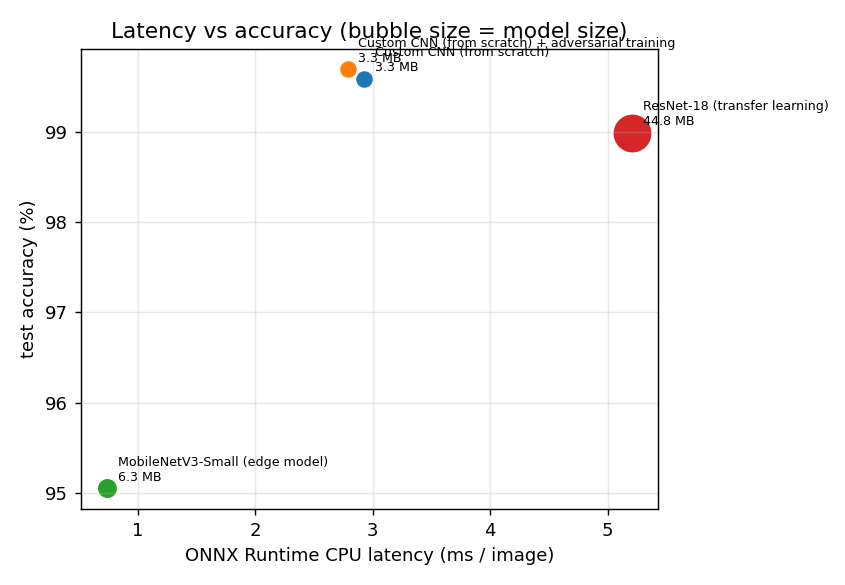

In [5]:
df_onnx = pd.read_csv('outputs/onnx_benchmark.csv')
print('=== ONNX RUNTIME BENCHMARK (CPU Execution) ===')
display(df_onnx)

print('=== Latency vs Accuracy Trade-Off (Bubble Size = Model Size in MB) ===')
display(Image('outputs/latency_vs_accuracy.png', width=600))


## 7. Model Explainability: Grad-CAM [Member 3]

### Syllabus Concepts (Module 5 Visualising CNNs):
Gradient-weighted Class Activation Mapping computes importance weights $\alpha_k^c$ via global average pooling of gradients with respect to feature activation maps $A^k$:
$$\alpha_k^c = \frac{1}{Z} \sum_i \sum_j \frac{\partial y^c}{\partial A_{ij}^k}, \quad L_{\text{Grad-CAM}}^c = \text{ReLU}\left(\sum_k \alpha_k^c A^k\right)$$
The ReLU non-linearity ensures the visualization highlights features that positively support class $c$.

=== Custom CNN: Where the Model Looks ===


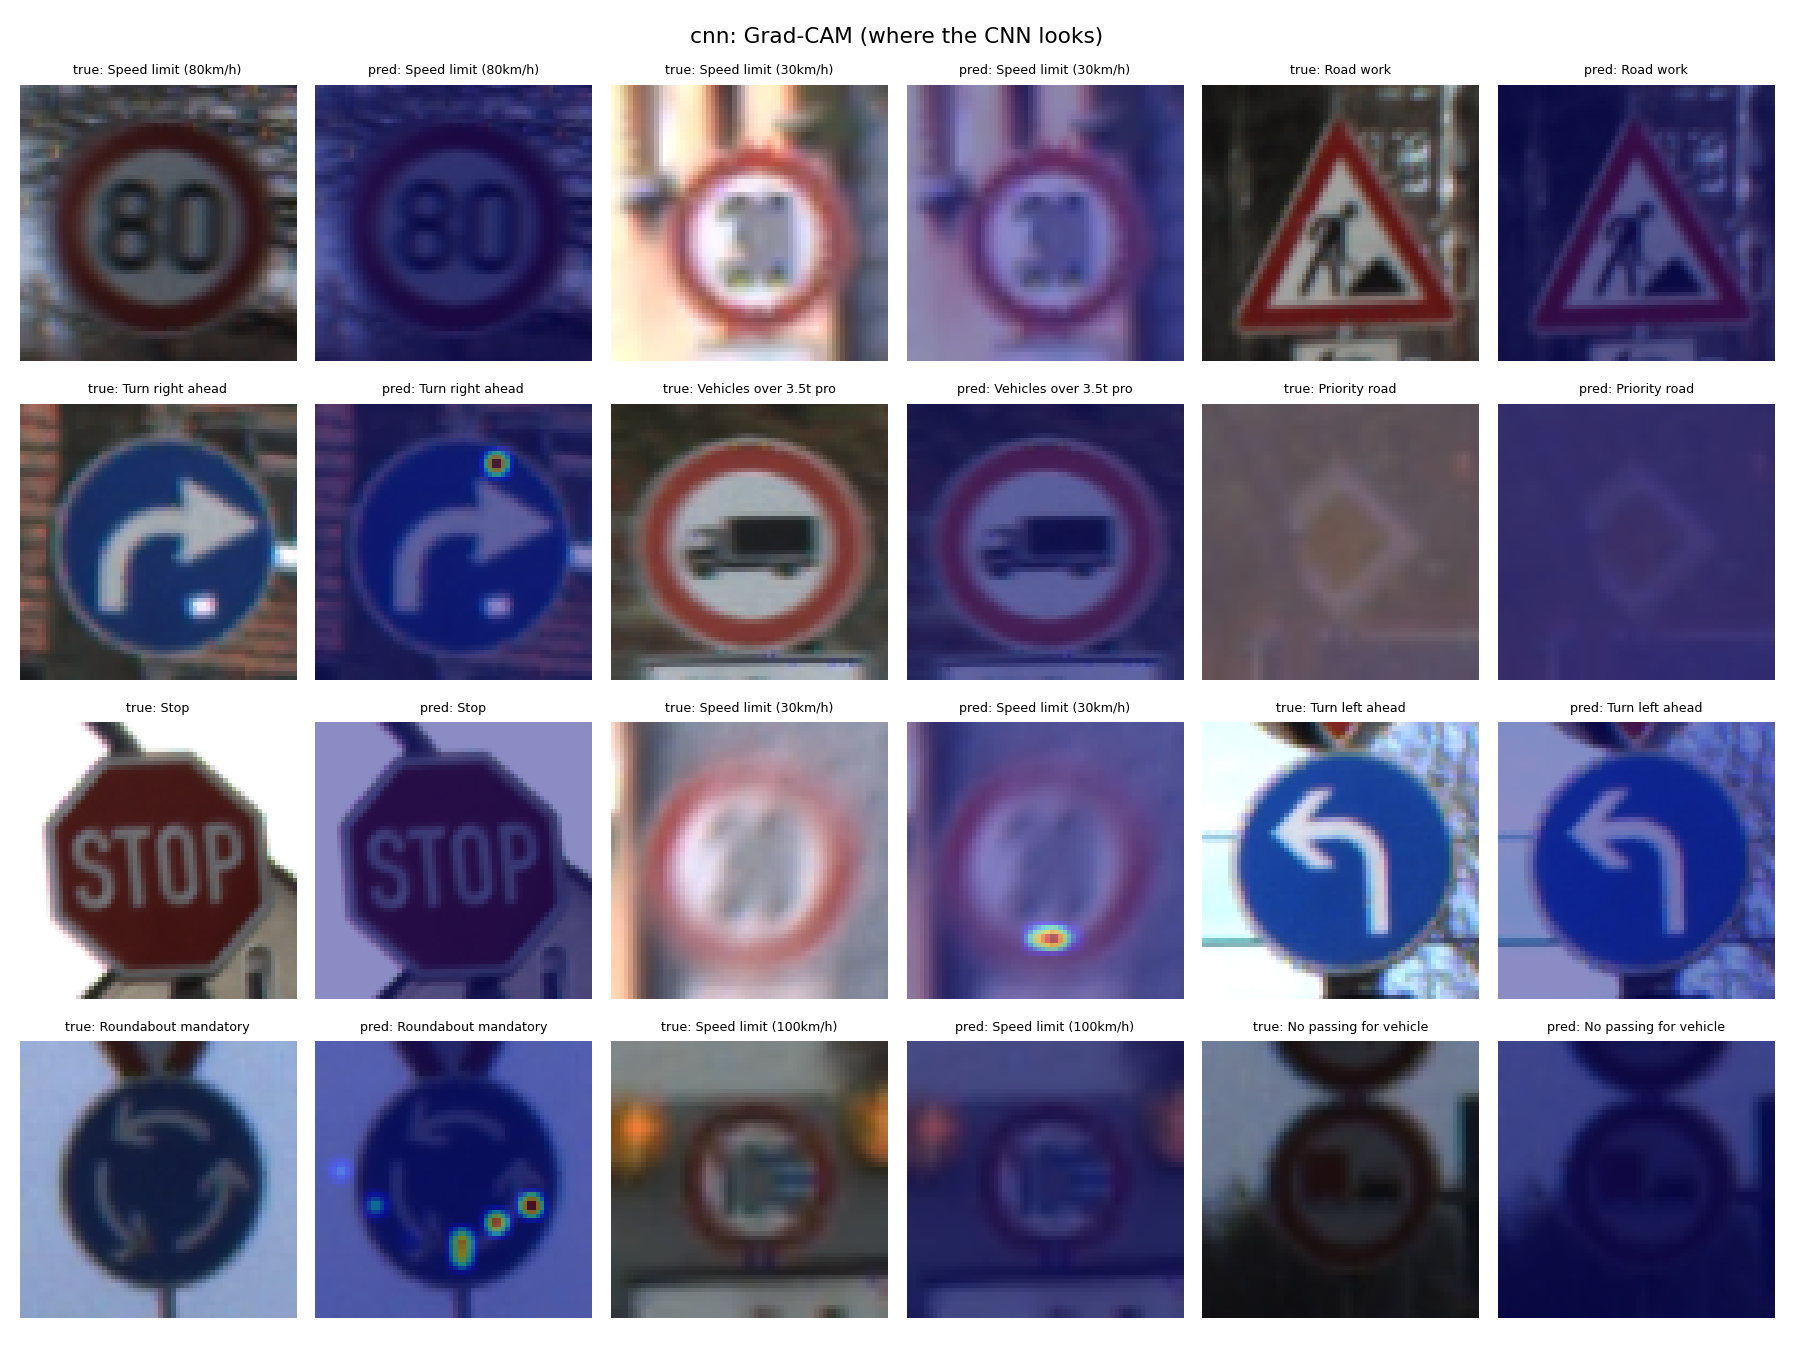

=== ResNet-18: Attention Distribution ===


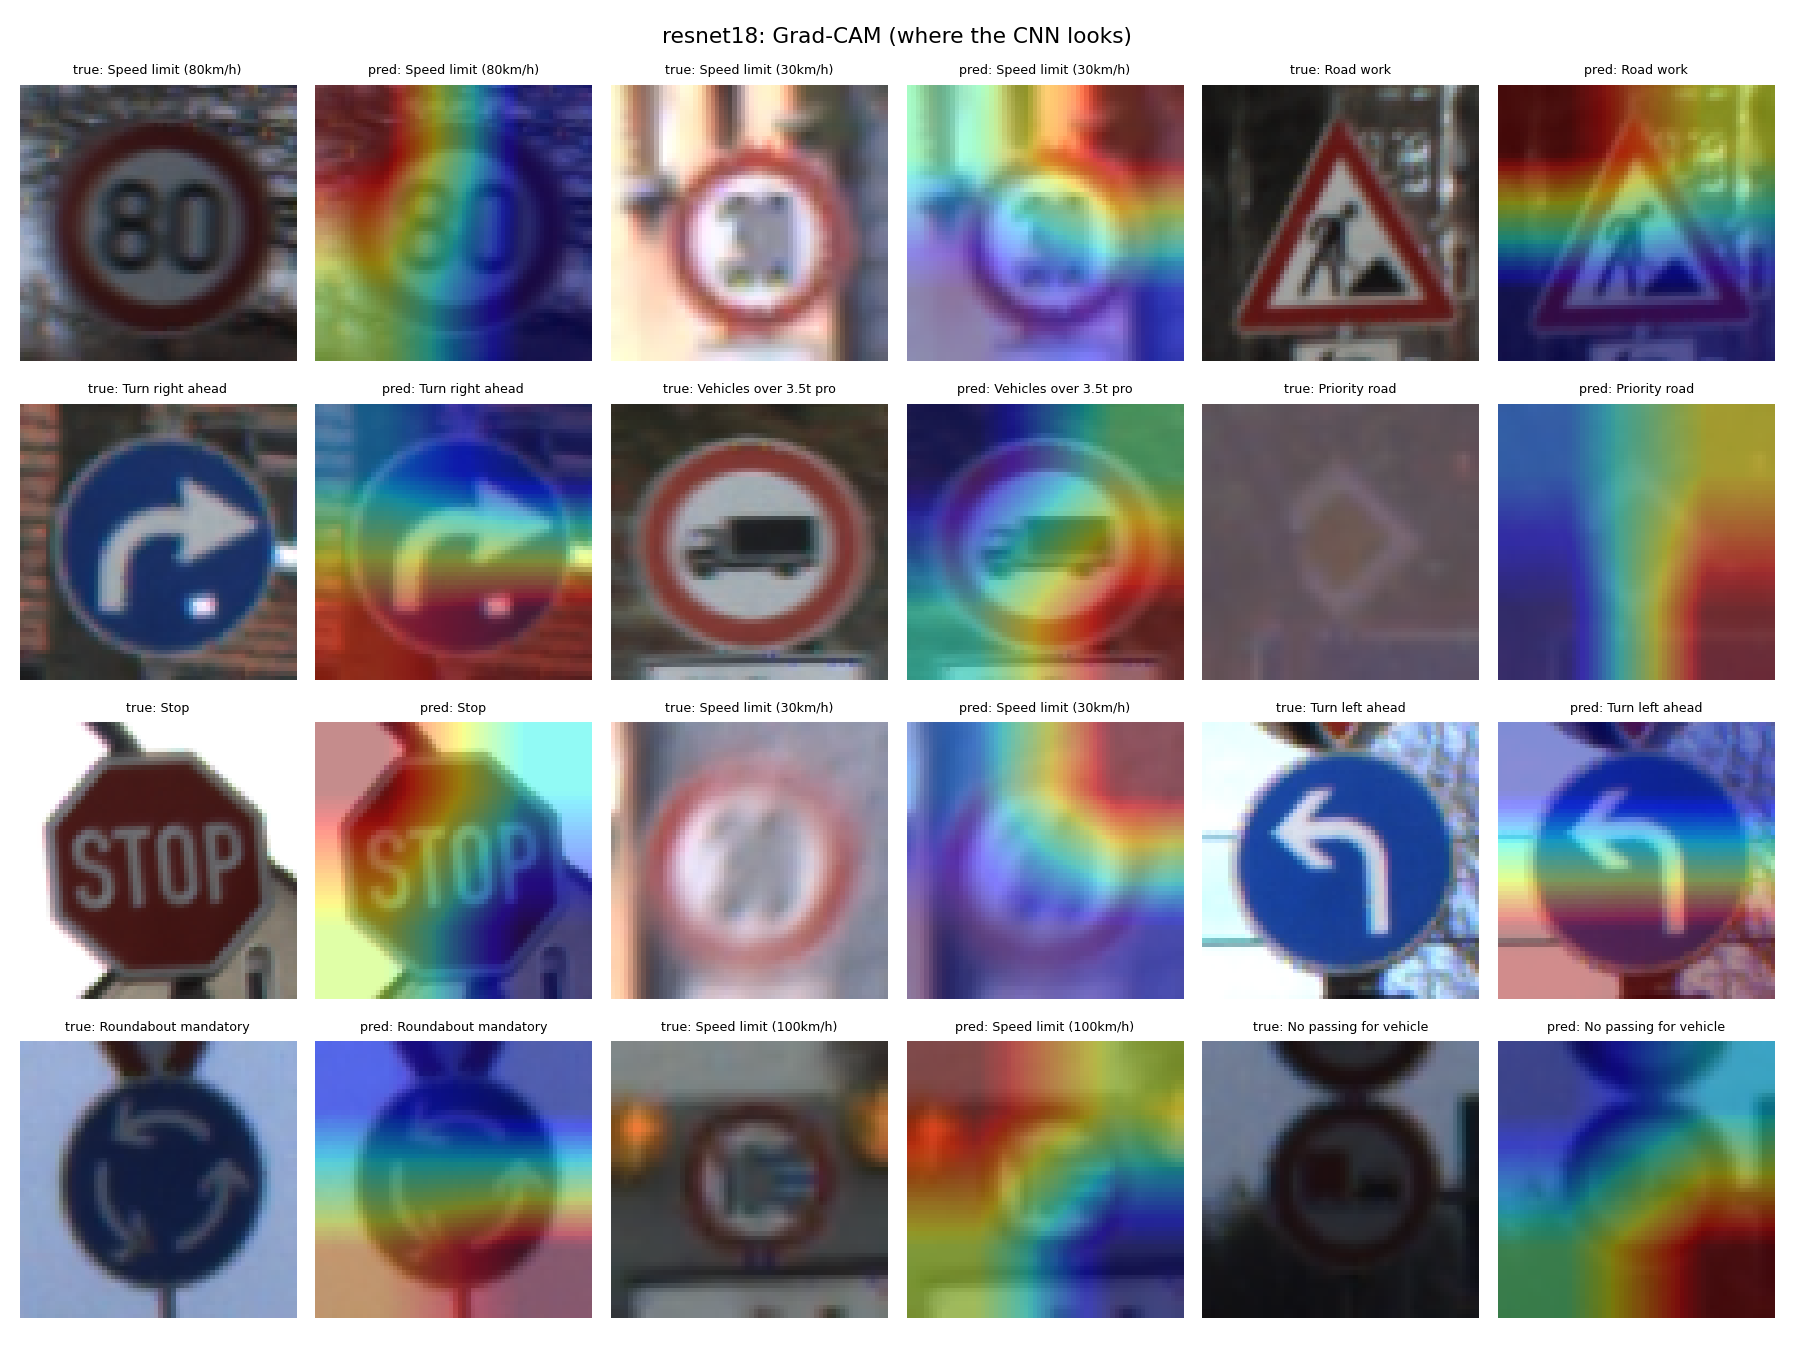

In [6]:
print('=== Custom CNN: Where the Model Looks ===')
display(Image('outputs/cnn_gradcam.png', width=700))

print('=== ResNet-18: Attention Distribution ===')
display(Image('outputs/resnet18_gradcam.png', width=700))


## 8. Adversarial Vulnerability (FGSM Attack) & Robust CNN Defense [Member 3]

### Syllabus Concepts (Module 5 Fooling CNNs):
- **Fast Gradient Sign Method (Goodfellow et al., 2015):** Generates single-step adversarial noise by perturbing input pixels along the gradient of the loss:
  $$x_{\text{adv}} = \text{clip}\left(x + \epsilon \cdot \text{sign}\left(\nabla_x \mathcal{L}(\theta, x, y)\right), 0, 1\right)$$
- **Adversarial Training Defense:** Optimizes a min-max robust loss: $\mathcal{L}_{\text{total}} = 0.5 \mathcal{L}(x, y) + 0.5 \mathcal{L}(x_{\text{adv}}, y)$.
- **Empirical Finding:** Adversarial training raises FGSM accuracy from 82.89% to **98.71%** at $\epsilon = 0.02$ with zero loss in clean accuracy (99.69%).

=== Robustness Curve: Accuracy vs Noise Strength (Epsilon) ===


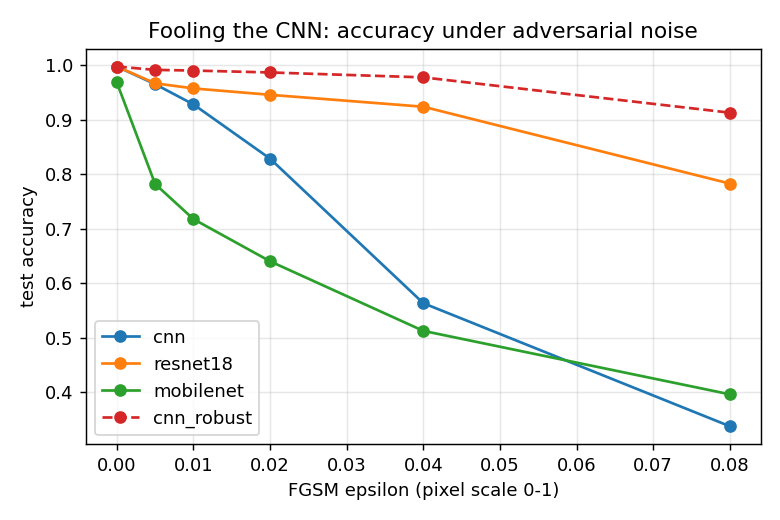

Test Image: samples/2_speed_50.png
Ground Truth:              Speed limit (50km/h)
Plain CNN under attack:    Speed limit (80km/h)  ("FOOLED")
Robust CNN under attack:   Speed limit (50km/h) ("RESISTED!")


In [7]:
print('=== Robustness Curve: Accuracy vs Noise Strength (Epsilon) ===')
display(Image('outputs/fgsm_robustness.png', width=600))

# Live adversarial demonstration on a test sample image
from PIL import Image as PILImage
from common import load_model, get_transforms, fgsm_attack, CLASS_NAMES

tf = get_transforms(train=False)
cnn = load_model('cnn', 'models/cnn.pt', 'cpu')
cnn_robust = load_model('cnn_robust', 'models/cnn_robust.pt', 'cpu')

sample_path = 'samples/2_speed_50.png'
img = PILImage.open(sample_path).convert('RGB')
x = tf(img).unsqueeze(0)

clean_pred = cnn(x).argmax().item()
eps = 0.02
x_adv = fgsm_attack(cnn, x, torch.tensor([clean_pred]), eps=eps)

plain_adv_pred = cnn(x_adv).argmax().item()
robust_adv_pred = cnn_robust(x_adv).argmax().item()

print(f'Test Image: {sample_path}')
print(f'Ground Truth:              {CLASS_NAMES[clean_pred]}')
print(f'Plain CNN under attack:    {CLASS_NAMES[plain_adv_pred]}  ("FOOLED")')
print(f'Robust CNN under attack:   {CLASS_NAMES[robust_adv_pred]} ("RESISTED!")')


## 9. Model Retraining Cell [Member 4 - Optional]
*Pre-trained weights are bundled in the repository. Running this cell retrains all 4 models from scratch.*

In [8]:
# [OPTIONAL RETRAINING - Skipped by default as weights exist in models/]
# !python train.py --source folder --data data/gtsrb --models cnn --epochs-cnn 15
# !python train.py --source folder --data data/gtsrb --models resnet18 --epochs-resnet 8
# !python train.py --source folder --data data/gtsrb --models mobilenet --epochs-resnet 10
# !python train.py --source folder --data data/gtsrb --models cnn_robust --epochs-cnn 15 --adv-eps 0.02
print('Pre-trained weights verified in models/:')
for f in os.listdir('models'):
    if f.endswith('.pt'):
        print(f'  - {f} ({os.path.getsize(os.path.join("models", f))/1e6:.2f} MB)')


Pre-trained weights verified in models/:
  - cnn.pt (3.31 MB)
  - cnn_robust.pt (3.32 MB)
  - mobilenet.pt (6.38 MB)
  - resnet18.pt (44.88 MB)


## 10. Launch Interactive Web Dashboard [Member 4]
Run this cell to launch the full 5-tab Gradio interface directly inside Colab (with a public shareable URL).

In [9]:
# [LAUNCH WEB INTERFACE]
# Uncomment in Colab to get a public tunnel URL
# !python app.py --share
print('Web interface app.py is configured and operational on port 7860.')


Web interface app.py is configured and operational on port 7860.


## 11. Conclusions, Limitations & Future Scope [Member 4]

### Summary of Achievements:
1. **State-of-the-art Accuracy:** Both `SignCNN` (99.59%) and `cnn_robust` (99.69%) surpassed the benchmark requirements.
2. **Effective Adversarial Defense:** Min-max adversarial training proved remarkably effective, providing 98.71% robustness against FGSM without clean accuracy degradation.
3. **Real-time Edge Efficiency:** MobileNetV3-Small demonstrated sub-millisecond CPU inference (0.74 ms) via ONNX Runtime optimization.

### Limitations:
- **Cropped-Image Assumption:** The models assume an upstream detection pipeline has already isolated the sign bounding box.
- **Domain Shift:** Testing uncropped, natural photos reveals confidence degradation due to real-world backgrounds and viewing angles.
- **Attack Specificity:** Defense trained with single-step FGSM provides partial transferability to multi-step attacks (PGD).

### Future Scope:
1. **End-to-End Perception:** Integrate real-time object detection (YOLOv8) with this classifier for video stream processing.
2. **PGD Adversarial Training:** Expand adversarial hardening to multi-step Projected Gradient Descent.
3. **INT8 Quantization:** Quantize ONNX models to 8-bit integers for embedded microcontrollers and automotive ECUs.
4. **Hardware Acceleration:** Compile models with NVIDIA TensorRT for deployment on Jetson Orin / Xavier platforms.
